# Evaluación 3 proyecto programado
## Daniel Coto Céspedes 
## Anthony Madrigal Salazar C34477

### Radiación de dipolo eléctrico: campos y transporte de energía

Partimos de

$$\vec p(t)=p_0\cos(\omega t)\,\hat z,\qquad \lambda=\frac{2\pi c}{\omega},\qquad t_0=t-\frac rc.$$

La aproximación de dipolo pequeño exige que el tamaño de la fuente sea mucho menor que $c/\omega$. Estudiamos puntos fuera de la fuente: $r>0$.


### Expresiones analíticas 

Tenemos los potenciales retardados:

$$V(r,\theta,t)=\frac{p_0\cos\theta}{4\pi\epsilon_0 r}\left[-\frac{\omega}{c}\sin\left[\omega\left(t-\frac rc\right)\right]+\frac{1}{r}\cos\left[\omega\left(t-\frac rc\right)\right]\right],$$

$$\vec A(\vec r,t)=-\frac{\mu_0p_0\omega}{4\pi r}\sin\left[\omega\left(t-\frac rc\right)\right]\hat z.$$

Aplicamos las relaciones:

$$\vec E=-\nabla V-\frac{\partial\vec A}{\partial t},\qquad \vec B=\nabla\times\vec A.$$

Al efectuar las derivadas obtenemos:

$$E_r=\frac{2p_0\cos\theta}{4\pi\epsilon_0}\left[\frac{\cos(\omega t_0)}{r^3}-\frac{\omega}{c}\frac{\sin(\omega t_0)}{r^2}\right]$$

$$E_\theta=\frac{p_0\sin\theta}{4\pi\epsilon_0}\left[\frac{\cos(\omega t_0)}{r^3}-\frac{\omega}{c}\frac{\sin(\omega t_0)}{r^2}-\frac{\omega^2}{c^2}\frac{\cos(\omega t_0)}{r}\right]$$

$$B_\phi=-\frac{\mu_0p_0\omega\sin\theta}{4\pi}\left[\frac{\sin(\omega t_0)}{r^2}+\frac{\omega}{c}\frac{\cos(\omega t_0)}{r}\right]$$

Por simetría, $E_\phi=B_r=B_\theta=0$ y

$$\vec E=E_r\hat r+E_\theta\hat\theta,\qquad \vec B=B_\phi\hat\phi.$$

Tenemos los límites de radiación (solo términos $1/r$):

$$\vec E_{\mathrm{rad}}=-\frac{\mu_0p_0\omega^2\sin\theta}{4\pi r}\cos(\omega t_0)\,\hat\theta,\qquad
\vec B_{\mathrm{rad}}=-\frac{\mu_0p_0\omega^2\sin\theta}{4\pi cr}\cos(\omega t_0)\,\hat\phi.$$

En adelante, para facilitar las gráficas usamos únicamente dentro del código la cantidad $kr=\omega r/c=2\pi r/\lambda$. Así se comparan distancias sin fijar valores arbitrarios de $p_0$ y $\omega$.


### Predicción antes de generar las figuras (apartado 4.1)

- Región cercana: $r\ll c/\omega=\lambda/(2\pi)$, de modo que $\omega r/c\ll 1$. Se espera que el campo eléctrico tenga la forma característica de un dipolo, dominada por $1/r^3$. El campo magnético comienza en $1/r^2$. En algunos puntos o tiempos un término puede anularse por la fase, la comparación de potencias de $r$ describe la tendencia general.
- Transición: $r\sim\lambda/(2\pi)$, donde $\omega r/c\sim1$. Las contribuciones $1/r^3$, $1/r^2$ y $1/r$ pueden ser comparables.
- Radiación: $r\gg\lambda$ (por tanto, $\omega r/c\gg1$). Se espera $E_r$ despreciable frente a $E_\theta$, campos $\vec E$ y $\vec B$ transversales, en fase, con amplitudes proporcionales a $1/r$.

Predicción 1: las flechas de $\vec E$ deben dejar de mostrar una componente radial importante al alejarnos.

Predicción 2: la alternancia espacial de signo de $B_\phi$ y la dependencia común $1/r$ serán más visibles en la región de radiación.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

plt.rcParams.update({"figure.dpi": 120, "axes.grid": False})

def campos_esfericos(rho, theta, u=0.0):
    psi = u - rho
    a = np.cos(psi) / rho**3 - np.sin(psi) / rho**2
    er = 2 * np.cos(theta) * a
    et = np.sin(theta) * (a - np.cos(psi) / rho)
    bp = np.sin(theta) * (-np.sin(psi) / rho**2 - np.cos(psi) / rho)
    return er, et, bp

def campos_plano(x, z, u=0.0, radio_minimo=0.05):
    rho = np.hypot(x, z)
    valido = rho >= radio_minimo
    rr = np.where(valido, rho, 1.0)
    st, ct = x / rr, z / rr  
    theta = np.arccos(np.clip(ct, -1, 1))
    er, et, bp = campos_esfericos(rr, theta, u)
    s = np.abs(st)
    ex = er * st + et * ct * np.sign(np.where(x == 0, 1., x))
    ez = er * ct - et * s
    by = bp * np.sign(np.where(x == 0, 1., x))
    return tuple(np.where(valido, a, np.nan) for a in (ex, ez, by))

def poynting_esferico(rho, theta, u=0.0):
    er, et, bp = campos_esfericos(rho, theta, u)
    return et * bp, -er * bp  
    
def poynting_promedio(rho, theta):
    return np.sin(theta)**2 / (2 * rho**2)

### Comparación de las dependencias radiales

En un instante y ángulo cualquiera, las contribuciones tienen las envolventes $r^{-3}$ (campo eléctrico cercano), $r^{-2}$ (inducción) y $r^{-1}$ (radiación). La gráfica muestra dependencias radiales normalizadas, no intensidades físicas absolutas, pues los coeficientes dependen de $p_0$, $\omega$, $\theta$ y $t_0$.

El eje horizontal es $\omega r/c$; las referencias $\omega r/c=1$ y $\omega r/c=2\pi$ corresponden respectivamente a $r=\lambda/(2\pi)$ y $r=\lambda$.


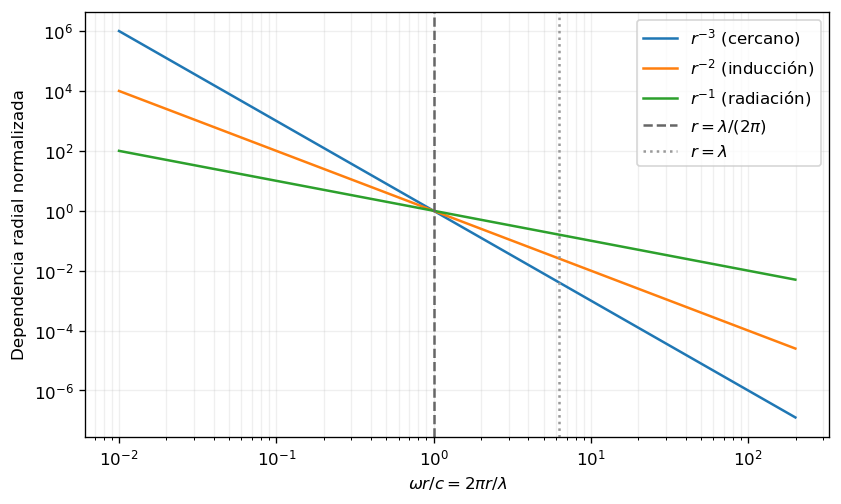

In [11]:
kr = np.logspace(-2, 2.3, 600)
fig, ax = plt.subplots(figsize=(8, 4.6))
for exponente, etiqueta in [(3, r"$r^{-3}$ (cercano)"), (2, r"$r^{-2}$ (inducción)"), (1, r"$r^{-1}$ (radiación)")]:
    ax.loglog(kr, kr**(-exponente), label=etiqueta)
ax.axvline(1, color="0.4", ls="--", label=r"$r=\lambda/(2\pi)$")
ax.axvline(2*np.pi, color="0.6", ls=":", label=r"$r=\lambda$")
ax.set(xlabel=r"$\omega r/c = 2\pi r/\lambda$", ylabel="Dependencia radial normalizada")
ax.grid(alpha=0.2, which="both"); ax.legend(); plt.show()

### Mapas de campos en el plano $y=0$

Se representa el plano $xz$, con el dipolo orientado en $\hat z$. En la primera fila el color muestra $\log_{10}|\vec E|$ y las flechas muestran su orientación; la segunda fila representa la componente $B_y$ mediante colores positivos y negativos.

Lectura de los ejes: Se usan $\omega x/c$ y $\omega z/c$ para que el aspecto gráfico sea independiente de las unidades elegidas. La escala cambia entre columnas. La región alrededor del origen se excluye porque el modelo dipolar puntual diverge cuando $r\to0$.

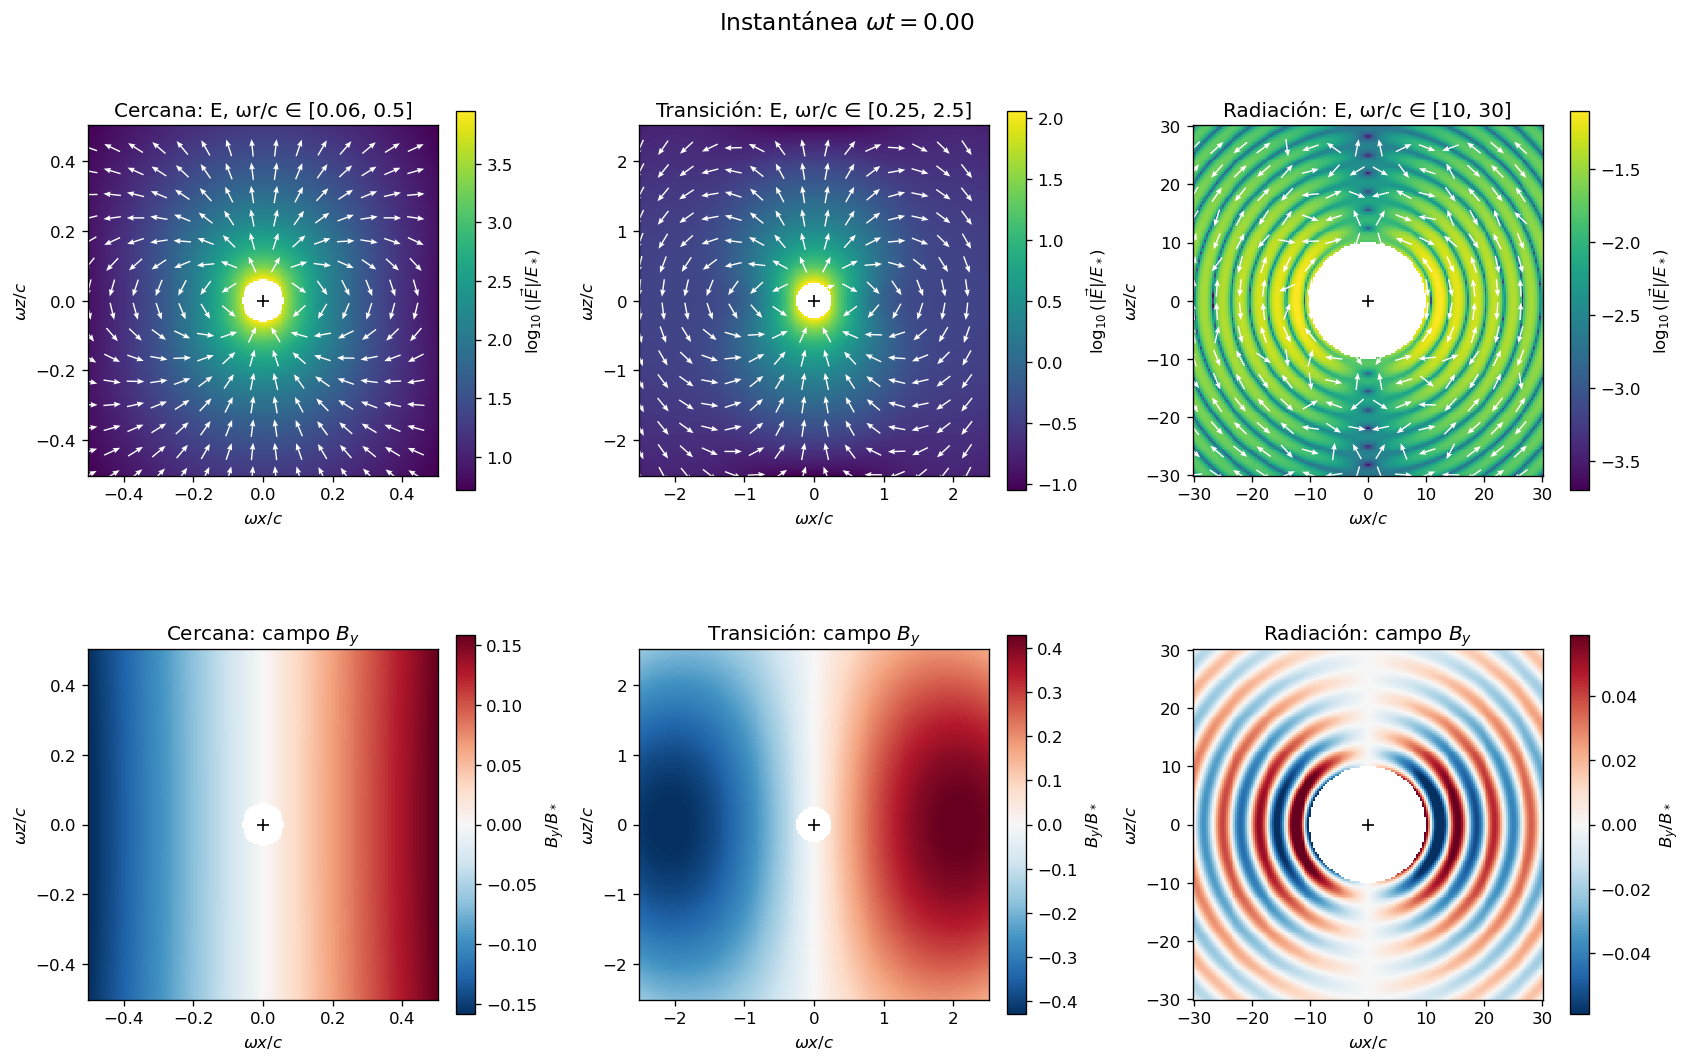

In [16]:
def mapa_regimen(ax, u, rmin, rmax, campo="E"):
    N=180
    q=np.linspace(-rmax,rmax,N)
    xx,zz=np.meshgrid(q,q)
    ex,ez,by=campos_plano(xx,zz,u,radio_minimo=rmin)
    ann=(np.hypot(xx,zz)>=rmin)
    if campo == "E":
        M=np.hypot(ex,ez)
        dat=np.log10(np.where(ann, M, np.nan))
        im=ax.pcolormesh(xx,zz,dat,shading="auto",cmap="viridis")
        step=12
        X,Z=xx[::step,::step],zz[::step,::step]
        Ex,Ez=ex[::step,::step],ez[::step,::step]
        Eabs=np.hypot(Ex,Ez)
        valid=np.isfinite(Eabs)&(Eabs>0)
        ax.quiver(X[valid],Z[valid],Ex[valid]/Eabs[valid],Ez[valid]/Eabs[valid],
                  color="white",pivot="mid",scale=20,width=.004,headwidth=4)
    else:
        lim=np.nanpercentile(np.abs(by),98)
        lim=max(lim,1.e-15)
        im=ax.pcolormesh(xx,zz,by,shading="auto",cmap="RdBu_r",vmin=-lim,vmax=lim)
    ax.plot(0,0,"k+",ms=7)
    ax.set_aspect("equal");ax.set_xlabel(r"$\omega x/c$");ax.set_ylabel(r"$\omega z/c$")
    return im


def visualizar_regimenes(u=0.0):
    zonas=[("Cercana",.06,.5),("Transición",.25,2.5),("Radiación",10.,30.)]
    fig,axes=plt.subplots(2,3,figsize=(14,9),constrained_layout=True)
    for j,(name,rmin,rmax) in enumerate(zonas):
        m=mapa_regimen(axes[0,j],u,rmin,rmax,"E")
        axes[0,j].set_title(f"{name}: E, ωr/c ∈ [{rmin:g}, {rmax:g}]")
        fig.colorbar(m, ax=axes[0,j], shrink=.74,
             label=r"$\log_{10}(|\vec{E}|/E_*)$")
        m=mapa_regimen(axes[1,j],u,rmin,rmax,"B")
        axes[1,j].set_title(f"{name}: campo $B_y$")
        fig.colorbar(m,ax=axes[1,j],shrink=.74,label=r"$B_y/B_*$")
    fig.suptitle(rf"Instantánea $\omega t={u:.2f}$",fontsize=14)
    plt.savefig("campo_electrico.pdf", bbox_inches="tight")
    plt.show()

visualizar_regimenes(u=0.0)

### Comprobación cuantitativa del carácter transversal

En $\theta=45^\circ$ comparamos el cociente $|E_r|/|E_\theta|$ (con la fase retardada escogida para evitar ceros accidentales) en varios radios. Un cociente pequeño indica un campo casi transversal, no es una definición de región de radiación por sí solo. La fase elegida es $\omega t_0=0$, de forma que los términos en seno se anulan en esta comparación puntual.


In [4]:
for radio in [0.2, 1.5, 2*np.pi, 20.0, 100.0]:
    er, et, bp = campos_esfericos(radio, np.pi/4, radio)
    print(f"omega*r/c = {radio:7.2f} | r/lambda = {radio/(2*np.pi):7.3f} | "
          f"|Er|/|Etheta| = {abs(er/et):.5f} | |Etheta|/|Bphi| (en unidades E*, B*) = {abs(et/bp):.5f}")

omega*r/c =    0.20 | r/lambda =   0.032 | |Er|/|Etheta| = 2.08333 | |Etheta|/|Bphi| (en unidades E*, B*) = 24.00000
omega*r/c =    1.50 | r/lambda =   0.239 | |Er|/|Etheta| = 1.60000 | |Etheta|/|Bphi| (en unidades E*, B*) = 0.55556
omega*r/c =    6.28 | r/lambda =   1.000 | |Er|/|Etheta| = 0.05198 | |Etheta|/|Bphi| (en unidades E*, B*) = 0.97467
omega*r/c =   20.00 | r/lambda =   3.183 | |Er|/|Etheta| = 0.00501 | |Etheta|/|Bphi| (en unidades E*, B*) = 0.99750
omega*r/c =  100.00 | r/lambda =  15.915 | |Er|/|Etheta| = 0.00020 | |Etheta|/|Bphi| (en unidades E*, B*) = 0.99990


### Vector de Poynting y su promedio temporal

A partir de las componentes de los campos,

$$\vec S=\frac{1}{\mu_0}(\vec E\times\vec B)=\frac{1}{\mu_0}\left(E_\theta B_\phi\,\hat r-E_rB_\phi\,\hat\theta\right)$$

Tomamos el resultado de la región de radiación:

$$\langle\vec S\rangle=\frac{\mu_0p_0^2\omega^4\sin^2\theta}{32\pi^2cr^2}\,\hat r$$

Para las figuras definimos en el código $E_*=p_0(\omega/c)^3/(4\pi\epsilon_0)$, $B_*=E_*/c$ y $S_*=E_*B_*/\mu_0$. Se muestran las componentes de $\vec S/S_*$; estos factores solo normalizan las gráficas.


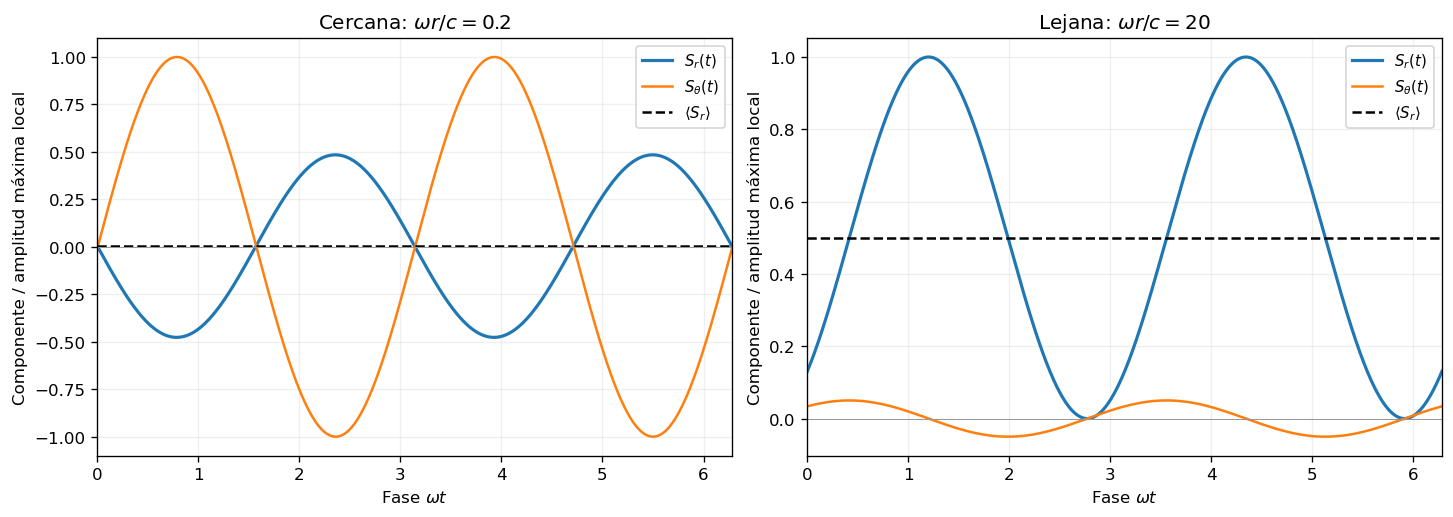

ωr/c=0.2: <S_r>/S* = 6.25; r/lambda = 0.0318
ωr/c=20: <S_r>/S* = 0.000625; r/lambda = 3.1831
Cociente <S_r>(cercana) / <S_r>(lejana) = 9999.999999999996


In [5]:
def graficar_poynting():
    u=np.linspace(0,2*np.pi,900)
    theta=np.pi/4
    puntos=[(.2,r"Cercana: $ωr/c=0.2$"),(20.,r"Lejana: $ωr/c=20$")]
    fig,axs=plt.subplots(1,2,figsize=(12,4.2),constrained_layout=True)
    for ax,(rho,label) in zip(axs,puntos):
        sr,st=poynting_esferico(rho,theta,u)
        scale=max(np.max(np.abs(sr)),np.max(np.abs(st)))
        ax.plot(u,sr/scale,label=r"$S_r(t)$",lw=1.9)
        ax.plot(u,st/scale,label=r"$S_\theta(t)$",lw=1.5)
        ax.axhline(poynting_promedio(rho,theta)/scale,color="black",ls="--",label=r"$\langle S_r\rangle$")
        ax.axhline(0,color="0.6",lw=.6)
        ax.set(title=label,xlabel=r"Fase $\omega t$",ylabel="Componente / amplitud máxima local",xlim=(0,2*np.pi))
        ax.grid(alpha=.2);ax.legend(fontsize=9)
    plt.show()
    for rho,_ in puntos:
        print(f"ωr/c={rho:g}: <S_r>/S* = {poynting_promedio(rho,theta):.6g}; "
              f"r/lambda = {rho/(2*np.pi):.4f}")
    print("Cociente <S_r>(cercana) / <S_r>(lejana) =",
          poynting_promedio(.2,theta)/poynting_promedio(20,theta))

graficar_poynting()

### Orientación relativa de $\vec E$, $\vec B$ y $\hat r$ en radiación

Tenemos $\vec E_{\mathrm{rad}}\parallel\hat\theta$ y $\vec B_{\mathrm{rad}}\parallel\hat\phi$; ambas direcciones son perpendiculares a $\hat r$ y entre sí. Como $\hat\theta\times\hat\phi=\hat r$, el vector $\vec S$ apunta hacia fuera.

Además, $|E_{\mathrm{rad}}|/|B_{\mathrm{rad}}|=c$.
Se comprueba a continuación el cociente con las expresiones completas en $\theta=90^\circ$ y un punto lejano.


In [7]:
rho=25.
theta=np.pi/2
u=rho  # psi = u-rho = 0
Er,Et,Bp=campos_esfericos(rho,theta,u)
print(f"ωr/c={rho:g}, theta=90°: Er/E*={Er:.4e}, Etheta/E*={Et:.4e}, Bphi/B*={Bp:.4e}")
print(f"Etheta/(c Bpsi) = {Et/Bp:.8f}  (tiende a 1 al alejarse)")

ωr/c=25, theta=90°: Er/E*=7.8377e-21, Etheta/E*=-3.9936e-02, Bphi/B*=-4.0000e-02
Etheta/(c Bpsi) = 0.99840000  (tiende a 1 al alejarse)


### Patrón angular de radiación 

A partir de $\langle\vec S\rangle$ y $dP/d\Omega=r^2\langle S_r\rangle$:

$$\frac{d\langle P\rangle}{d\Omega}=\frac{\mu_0p_0^2\omega^4}{32\pi^2c}\sin^2\theta$$

Se estudia el valor relativo $[d\langle P\rangle/d\Omega]/[d\langle P\rangle/d\Omega]_{\max}=\sin^2\theta$. El máximo ocurre para $\theta=\pi/2$ y se anula para $\theta=0,\pi$, de acuerdo con la diapositiva 13. El factor angular procede de $\sin\theta$ en $E_\theta$ y $B_\phi$.

Se tiene también la potencia total promedio:

$$\langle P\rangle=\frac{\mu_0p_0^2\omega^4}{12\pi c}$$


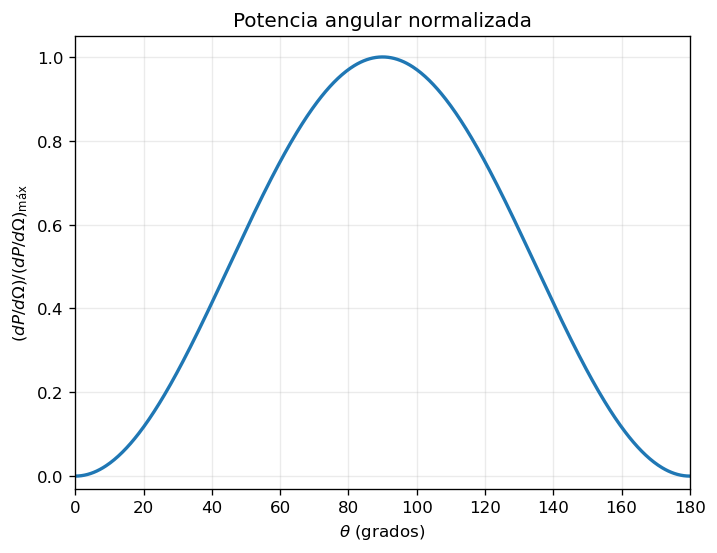

theta=  0°: (dP/dOmega)/(dP/dOmega)_max = 0.0000
theta= 30°: (dP/dOmega)/(dP/dOmega)_max = 0.2500
theta= 45°: (dP/dOmega)/(dP/dOmega)_max = 0.5000
theta= 60°: (dP/dOmega)/(dP/dOmega)_max = 0.7500
theta= 90°: (dP/dOmega)/(dP/dOmega)_max = 1.0000
theta=120°: (dP/dOmega)/(dP/dOmega)_max = 0.7500
theta=180°: (dP/dOmega)/(dP/dOmega)_max = 0.0000


In [17]:
theta=np.linspace(0,np.pi,600)
patron=np.sin(theta)**2
fig=plt.figure(figsize=(11,4.5),constrained_layout=True)
ang=np.linspace(0,2*np.pi,800)
ax2=fig.add_subplot(122)
ax2.plot(np.rad2deg(theta),patron,lw=2)
ax2.set(xlabel=r"$\theta$ (grados)",ylabel=r"$(dP/d\Omega)/(dP/d\Omega)_{\rm máx}$",
        title="Potencia angular normalizada",xlim=(0,180),ylim=(-.03,1.05))
ax2.grid(alpha=.25)
plt.show()
for deg in [0,30,45,60,90,120,180]:
    print(f"theta={deg:3d}°: (dP/dOmega)/(dP/dOmega)_max = {np.sin(np.deg2rad(deg))**2:.4f}")